<a href="https://colab.research.google.com/github/gchekwemoi/datascienceAssigmnet/blob/main/Assignment1_Chekwemoi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Science Lifecycle: Assignment 1
**Objective:** Use exploratory data analysis (EDA) and statistical techniques on `automobileEDA.csv` to find the features with the greatest impact on car price, and turn those findings into a pricing recommendation for a car dealer.

**Name** : Chekwemoi Gloria

**Course** : MSDS

**GITHUB Respitory** : https://github.com/gchekwemoi/datascienceAssigmnet




In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

## Loading the data



In [42]:
import pandas as pd

url = "https://raw.githubusercontent.com/gchekwemoi/datascienceAssigmnet/main/automobileEDA.csv"

df = pd.read_csv(url)

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (201, 29)


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,0.909722,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,0.919444,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,0.922222,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


---
## 1. Explore and clean the data


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    object 
 3   aspiration         201 non-null    object 
 4   num-of-doors       201 non-null    object 
 5   body-style         201 non-null    object 
 6   drive-wheels       201 non-null    object 
 7   engine-location    201 non-null    object 
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    object 
 14  num-of-cylinders   201 non-null    object 
 15  engine-size        201 non-null    int64  
 16  fuel-system        201 non

**Explanation.** The dataset has **201 cars and 29 columns**.

- **Continuous (numeric):** `wheel-base`, `length`, `width`, `height`, `curb-weight`, `engine-size`, `bore`, `stroke`, `compression-ratio`, `horsepower`, `peak-rpm`, `city-mpg`, `highway-mpg`, `city-L/100km`, `normalized-losses`.
- **Categorical:** `make`, `aspiration`, `num-of-doors`, `body-style`, `drive-wheels`, `engine-location`, `engine-type`, `num-of-cylinders`, `fuel-system`, `horsepower-binned`, plus `symboling`  `city-L/100km`, `city-mpg`

## 1.2 Missing values

In [44]:
missing = df.isna().sum()
print(missing[missing > 0])
print()


stroke               4
horsepower-binned    1
dtype: int64



In [45]:
print("Rows with missing 'stroke':")
print(df.loc[df["stroke"].isna(), ["make", "body-style", "engine-size", "stroke"]])
print()
print("Row with missing 'horsepower-binned':")
print(df.loc[df["horsepower-binned"].isnull(), ["make", "horsepower", "horsepower-binned"]])
print()
print("Horsepower range inside each bin:")
print(df.groupby("horsepower-binned")["horsepower"].agg(["min", "max", "count"]))

Rows with missing 'stroke':
     make body-style  engine-size  stroke
52  mazda  hatchback           70     NaN
53  mazda  hatchback           70     NaN
54  mazda  hatchback           70     NaN
55  mazda  hatchback           80     NaN

Row with missing 'horsepower-binned':
      make  horsepower horsepower-binned
46  jaguar       262.0               NaN

Horsepower range inside each bin:
                     min    max  count
horsepower-binned                     
High               156.0  207.0     23
Low                 48.0  101.0    115
Medium             102.0  155.0     62


**Explanation.** Only two columns have missing values:

- **`stroke`: 4 missing values**, all Mazda hatchbacks. `stroke` is a continuous engine measurement, so I replace the gaps with the **column mean**. With only 4 of 201 rows affected, this will not distort the distribution, and it keeps the rows (deleting them would throw away valid price information).
- **`horsepower-binned`: 1 missing value**, a Jaguar with 262 hp. The table of bin ranges shows that "High" starts at 156 hp, so a 262 hp car clearly belongs in **High**. I fill it with "High" because the correct value can be worked out from `horsepower`, which is better than guessing the most common category.

In [46]:
df["stroke"] = df["stroke"].fillna(df["stroke"].mean())
df["horsepower-binned"] = df["horsepower-binned"].fillna("High")

print("Missing values remaining:", df.isnull().sum().sum())

Missing values remaining: 0


**Explanation.** The total number of missing values is now **0**.

## 1.3 Duplicates

In [47]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate rows when ignoring price:", df.drop(columns="price").duplicated().sum())

Exact duplicate rows: 0
Duplicate rows when ignoring price: 7


**Explanation.** There are **no exact duplicate rows**, so nothing needs removing. The second check ignores `price`: **7 rows** share identical specifications with another car but have a different price. Because the prices differ, these are not true duplicates (they can be different trims or model years), so I keep them.

## 1.4 Outliers
I use the **IQR rule**: a value is an outlier if it falls below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR. I also use boxplots to see them.

In [48]:
num_cols = ["wheel-base", "curb-weight", "engine-size", "horsepower",
            "city-mpg", "highway-mpg", "price"]

# Identify outliers using the IQR method
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = df[(df[col] < Q1 - 1.5 * IQR) |
                  (df[col] > Q3 + 1.5 * IQR)]

    print(col, ":", len(outliers), "outliers")

wheel-base : 3 outliers
curb-weight : 2 outliers
engine-size : 10 outliers
horsepower : 5 outliers
city-mpg : 2 outliers
highway-mpg : 3 outliers
price : 14 outliers


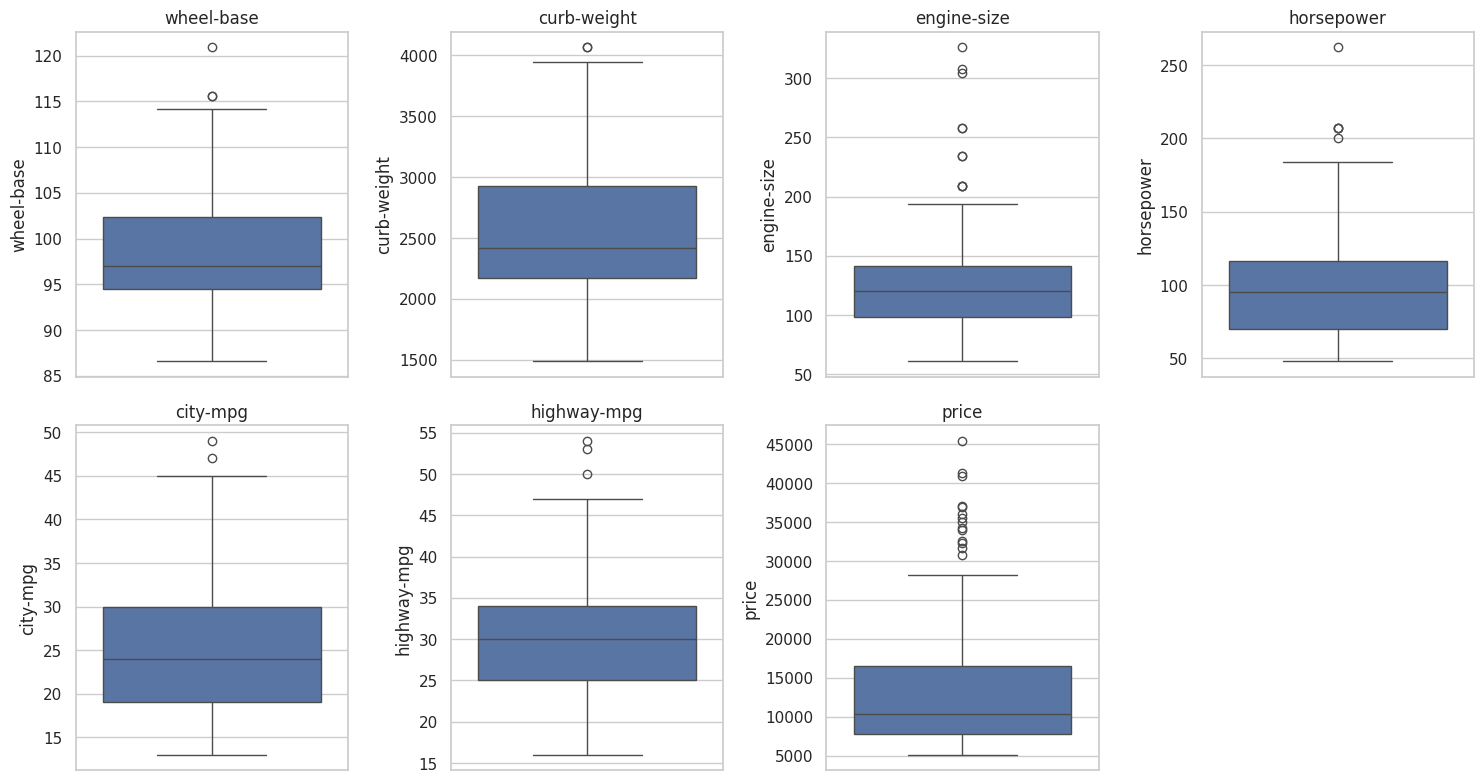

In [49]:
plt.figure(figsize=(15, 8))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

**Explanation.** Outliers appear in every numeric variable, with the most in `price` (14 cars) and `engine-size` (10 cars). Before deciding what to do, I check *which cars* they are.

In [50]:
q1, q3 = df["price"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
df.loc[df["price"] > upper, ["make", "body-style", "engine-size", "horsepower", "price"]].sort_values("price")

,make,body-style,engine-size,horsepower,price
14,bmw,sedan,209,182.0,30760.0
67,mercedes-benz,sedan,183,123.0,31600.0
44,jaguar,sedan,258,176.0,32250.0
123,porsche,hardtop,194,207.0,32528.0
124,porsche,hardtop,194,207.0,34028.0
68,mercedes-benz,sedan,234,155.0,34184.0
69,mercedes-benz,convertible,234,155.0,35056.0
45,jaguar,sedan,258,176.0,35550.0
46,jaguar,sedan,326,262.0,36000.0
16,bmw,sedan,209,182.0,36880.0


**Explanation and decision.** All 14 price outliers are **BMW, Mercedes-Benz, Jaguar and Porsche** models. These are real luxury cars with large engines and high horsepower, so they are **genuine observations, not data-entry errors**.

**Decision: I keep them.** Because luxury cars are exactly where price differs most, so removing them would hide the brand and engine effects the dealer needs to know about. T

## 1.5 Save the cleaned dataset

In [51]:
df.to_csv("Chekwemoi_Data.csv", index=False)

from google.colab import files
files.download("Chekwemoi_Data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Explanation.** The cleaned dataset (201 rows, 29 columns, no missing values or duplicates) is saved as `Chekwemoi_Data.csv`.

---
# Question 2: Descriptive statistics and patterns

## 2.1 Summary statistics for the continuous variables

In [52]:
cont_cols = ["price", "wheel-base", "length", "width", "height", "curb-weight",
             "engine-size", "bore", "stroke", "compression-ratio", "horsepower",
             "peak-rpm", "city-mpg", "highway-mpg", "city-L/100km", "normalized-losses"]

summary = df[cont_cols].describe().T
summary["median"] = df[cont_cols].median()
summary["skewness"] = df[cont_cols].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,median,skewness
price,201.0,13207.13,7947.07,5118.00,7775.00,10295.00,16500.00,45400.00,10295.00,1.81
wheel-base,201.0,98.80,6.07,86.60,94.50,97.00,102.40,120.90,97.00,1.03
length,201.0,0.84,0.06,0.68,0.80,0.83,0.88,1.00,0.83,0.15
width,201.0,0.92,0.03,0.84,0.89,0.91,0.92,1.00,0.91,0.88
height,201.0,53.77,2.45,47.80,52.00,54.10,55.50,59.80,54.10,0.03
curb-weight,201.0,2555.67,517.30,1488.00,2169.00,2414.00,2926.00,4066.00,2414.00,0.71
engine-size,201.0,126.88,41.55,61.00,98.00,120.00,141.00,326.00,120.00,1.98
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.58,3.94,3.31,-0.03
stroke,201.0,3.26,0.32,2.07,3.11,3.29,3.41,4.17,3.29,-0.70
compression-ratio,201.0,10.16,4.00,7.00,8.60,9.00,9.40,23.00,9.00,2.58


**Explanation**

- **Price:** The average price is approximately $13,207, while the median is $10,295. This suggests that prices are *right-skewed*, with a few expensive cars pulling the average upward. Prices range from **$5,118 to $45,400**, indicating considerable variation among the cars.

- **Engine size, curb weight and horsepower:** These variables have relatively high maximum values compared to their typical values. This indicates that the dataset includes some cars with *larger engines, heavier bodies and higher horsepower*.

- **City and highway MPG:** The average fuel economy is about **25 MPG in the city** and **31 MPG on the highway**. The variation reflects differences in fuel efficiency across the different types of cars.

- **Length and width:** These variables are expressed in *normalized form*, with values generally ranging between **0.8 and 1.0**. Therefore, they represent relative measurements rather than actual dimensions in centimetres.

In [53]:
cat_cols = ["make", "body-style", "drive-wheels", "aspiration", "num-of-doors",
            "engine-location", "engine-type", "num-of-cylinders", "fuel-system",
            "horsepower-binned", "symboling"]

for c in cat_cols:
    counts = df[c].value_counts()
    out = pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)})
    print(f"--- {c} ---")
    print(out, "\n")

--- make ---
               count  percent
make                         
toyota            32     15.9
nissan            18      9.0
mazda             17      8.5
mitsubishi        13      6.5
honda             13      6.5
subaru            12      6.0
volkswagen        12      6.0
volvo             11      5.5
peugot            11      5.5
dodge              9      4.5
mercedes-benz      8      4.0
bmw                8      4.0
plymouth           7      3.5
audi               6      3.0
saab               6      3.0
porsche            4      2.0
chevrolet          3      1.5
alfa-romero        3      1.5
jaguar             3      1.5
isuzu              2      1.0
renault            2      1.0
mercury            1      0.5 

--- body-style ---
             count  percent
body-style                 
sedan           94     46.8
hatchback       68     33.8
wagon           25     12.4
hardtop          8      4.0
convertible      6      3.0 

--- drive-wheels ---
              count  percen

**Explanation.** The market is dominated by a few categories:
- **Body style:** sedans (94) and hatchbacks (68) make up about 80% of cars; convertibles (6) and hardtops (8) are rare.
- **Drive wheels:** front-wheel drive (118) is most common, then rear-wheel drive (75); only 8 cars are 4-wheel drive.
- **Aspiration and cylinders:** 165 cars are standard (non-turbo) and 157 have four cylinders. Cars with 3, 8 or 12 cylinders are almost absent.
- **Make:** Toyota is the most common brand (32 cars), followed by Nissan (18) and Mazda (17). Several brands (Mercury, Renault, Isuzu) have only 1 to 2 cars.
- **Engine location:** almost every car has a front engine, so this variable will have little power to explain price differences.

Small categories (for example 4wd, convertible, 12 cylinders) mean that averages for those groups rest on very few cars and need to be read carefully.

## 2.3 Distribution of price and the other continuous variables

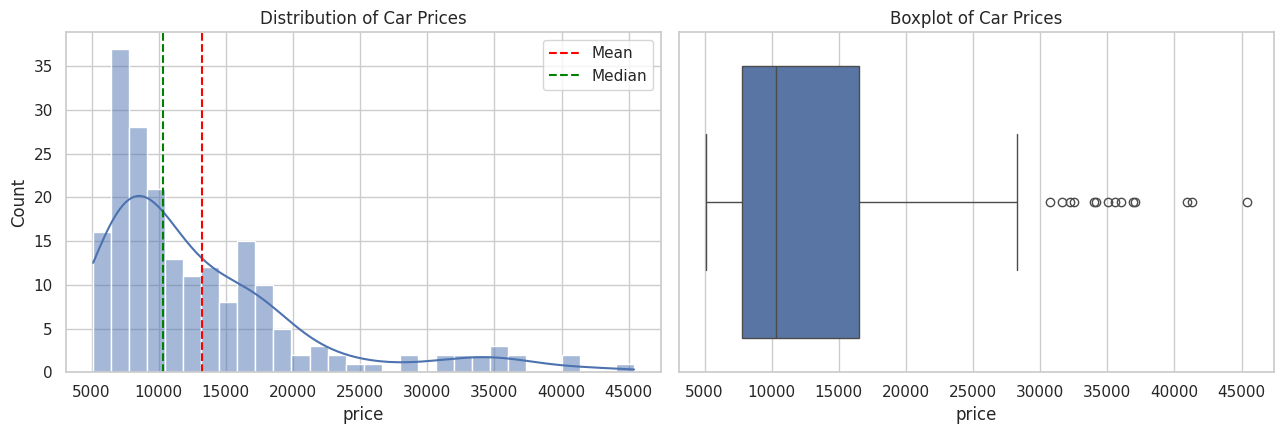

Skewness: 1.81


In [54]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Histogram
sns.histplot(df["price"], bins=30, kde=True, ax=axes[0])
axes[0].axvline(df["price"].mean(), color="red", linestyle="--", label="Mean")
axes[0].axvline(df["price"].median(), color="green", linestyle="--", label="Median")
axes[0].set_title("Distribution of Car Prices")
axes[0].legend()

# Boxplot
sns.boxplot(x=df["price"], ax=axes[1])
axes[1].set_title("Boxplot of Car Prices")

plt.tight_layout()
plt.show()

print("Skewness:", round(df["price"].skew(), 2))

**Explanation**

- **Histogram:** The distribution of car prices is *right-skewed*. Most cars are concentrated in the lower price range, while a few expensive cars extend the distribution to the right.
- **Mean and median:** The mean is higher than the median, confirming the presence of high-priced cars that influence the average.
- **Boxplot:** The boxplot shows several potential outliers among the higher-priced cars. These vehicles may represent luxury or high-performance models.
- **Skewness:** The positive skewness value indicates that the distribution has a longer tail towards higher prices.

Overall, car prices are not normally distributed, as a small number of expensive vehicles contribute to the right-skewed pattern.

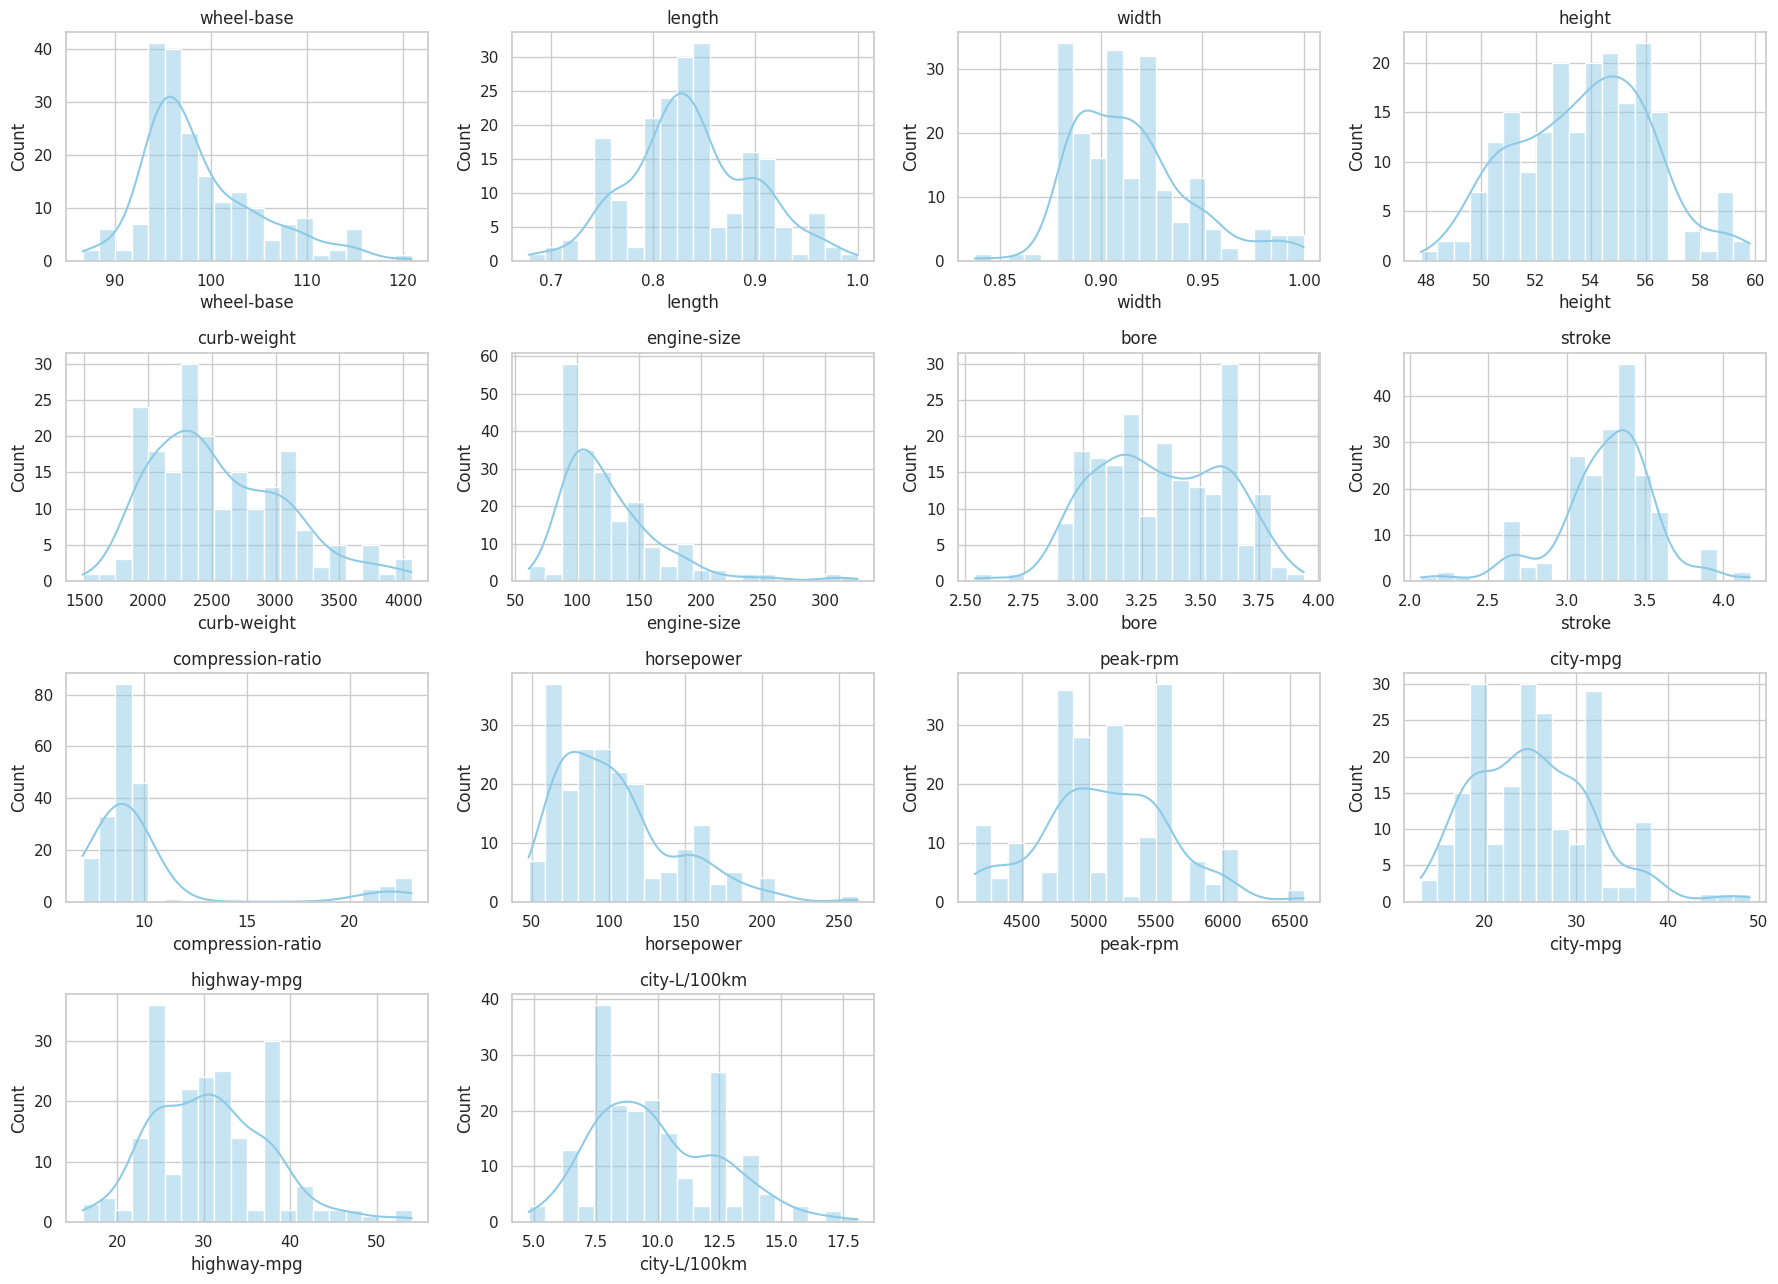

In [55]:
plot_cols = ["wheel-base", "length", "width", "height", "curb-weight", "engine-size",
             "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm",
             "city-mpg", "highway-mpg", "city-L/100km"]

fig, axes = plt.subplots(4, 4, figsize=(18, 13))
for ax, c in zip(axes.ravel(), plot_cols):
    sns.histplot(df[c], bins=20, kde=True, ax=ax, color="#8ecae6")
    ax.set_title(c)
for ax in axes.ravel()[len(plot_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

**Explanation**

The histograms show the distribution of the numerical variables in the automobile dataset.

- **Vehicle dimensions:** Variables such as *wheel-base, length, width and height* show differences in the physical sizes of the vehicles.
- **Weight and engine characteristics:** *Curb-weight, engine-size, bore, stroke and horsepower* indicate variations in vehicle performance and design.
- **Fuel efficiency:** *City-mpg, highway-mpg and city-L/100km* show differences in fuel consumption across the vehicles.
- **Distribution patterns:** Some variables appear approximately normally distributed, while others are *skewed* or have potential outliers.


## 2.4 Distribution of the categorical variables

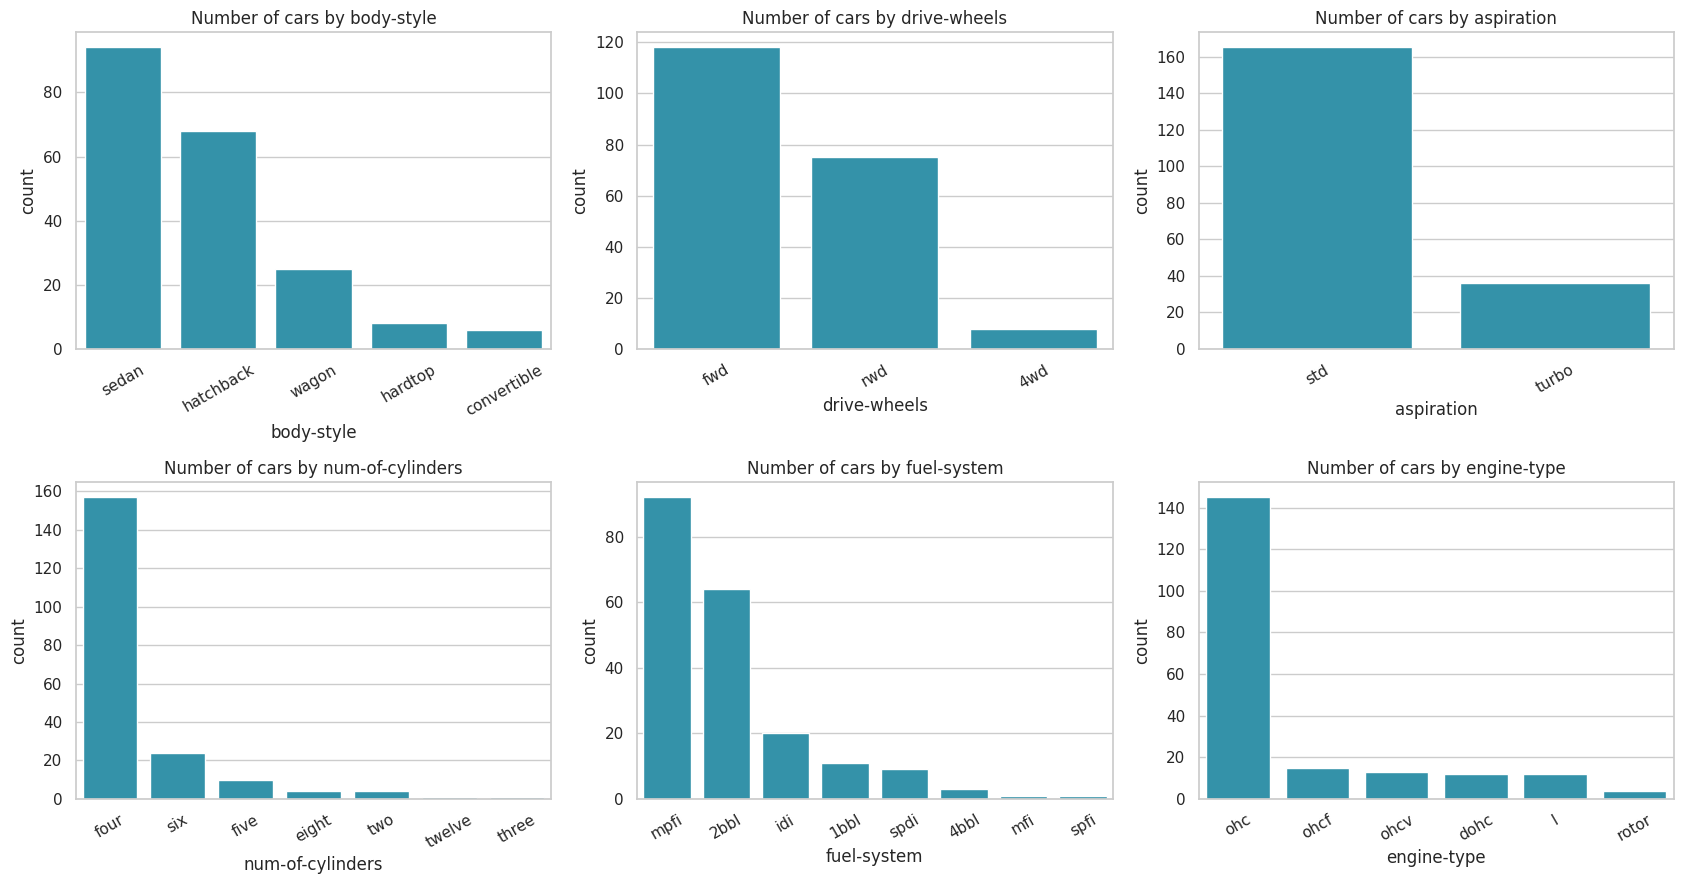

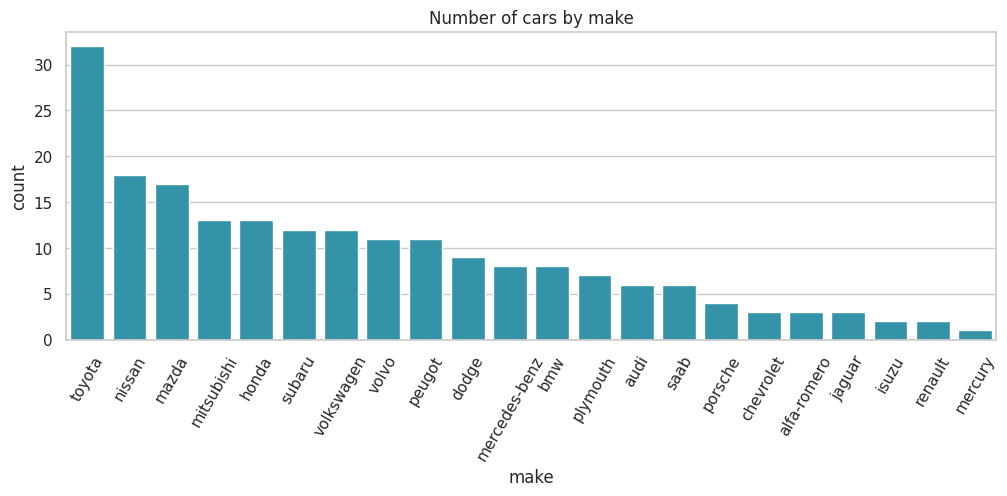

In [56]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, c in zip(axes.ravel(), ["body-style", "drive-wheels", "aspiration",
                                "num-of-cylinders", "fuel-system", "engine-type"]):
    order = df[c].value_counts().index
    sns.countplot(x=c, data=df, order=order, ax=ax, color="#219ebc")
    ax.set_title(f"Number of cars by {c}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

plt.figure(figsize=(12, 4))
sns.countplot(x="make", data=df, order=df["make"].value_counts().index, color="#219ebc")
plt.xticks(rotation=60); plt.title("Number of cars by make"); plt.show()

**Explanation.** The bar charts confirm the frequency tables visually: sedan and hatchback, front-wheel drive, standard aspiration, four cylinders, MPFI or 2-barrel fuel systems and OHC engines are the common choices. The dataset is therefore weighted toward ordinary family cars, with a small number of specialist and luxury cars.

## 2.5 Summary of patterns observed
1. Price is **right-skewed**: a few luxury cars (BMW, Mercedes-Benz, Jaguar, Porsche) pull the mean well above the median.
2. Size and power variables (`engine-size`, `horsepower`, `curb-weight`) have the same right-skewed shape as price, which suggests they are related.
3. The data is concentrated in a few categories (sedan/hatchback, FWD, 4 cylinders, standard aspiration), and some categories have very few cars.
4. `engine-location` is almost constant (only 3 rear-engine cars), so it is a weak basis for explaining price in general.

---
# Question 3: Average price by group


## 3.1 Average price by drive-wheels

              count     mean   median     min      max
drive-wheels                                          
rwd              75  19758.0  16900.0  6785.0  45400.0
4wd               8  10241.0   9006.0  7603.0  17450.0
fwd             118   9245.0   8192.0  5118.0  23875.0


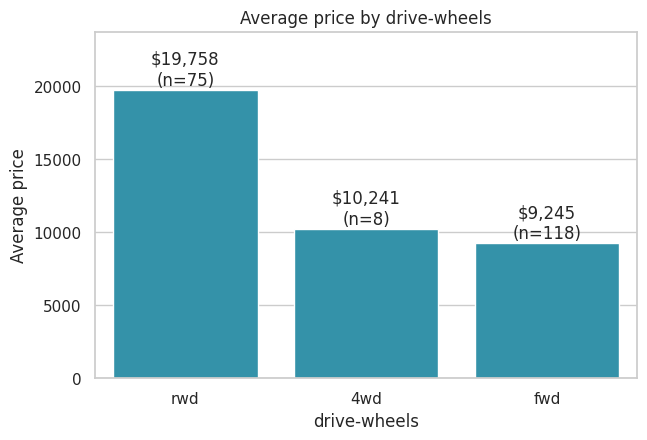

In [57]:
dw = (df.groupby("drive-wheels")["price"]
        .agg(["count", "mean", "median", "min", "max"])
        .round(0).sort_values("mean", ascending=False))
print(dw)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=dw.index, y=dw["mean"], ax=ax, color="#219ebc")
for i, (m, n) in enumerate(zip(dw["mean"], dw["count"])):
    ax.text(i, m + 300, f"${m:,.0f}\n(n={n})", ha="center")
ax.set_ylabel("Average price"); ax.set_title("Average price by drive-wheels")
ax.set_ylim(0, dw["mean"].max() * 1.2)
plt.show()

**Explanation.**
Rear-wheel drive cars are the most expensive on average about 19,758, roughly twice the price offront-wheel drive cars, which are the cheapest about $9,245. 4-wheel drive cars average about $10,241, but there are only 8 of them, so that figure is less reliable. Rear-wheel drive is typical of sports and luxury cars, which explains the premium.

## 3.2 Average price by body-style

             count     mean   median      min      max
body-style                                            
hardtop          8  22208.0  19688.0   8249.0  45400.0
convertible      6  21890.0  17084.0  11595.0  37028.0
sedan           94  14460.0  11078.0   5499.0  41315.0
wagon           25  12372.0  11694.0   6918.0  28248.0
hatchback       68   9957.0   8672.0   5118.0  22018.0


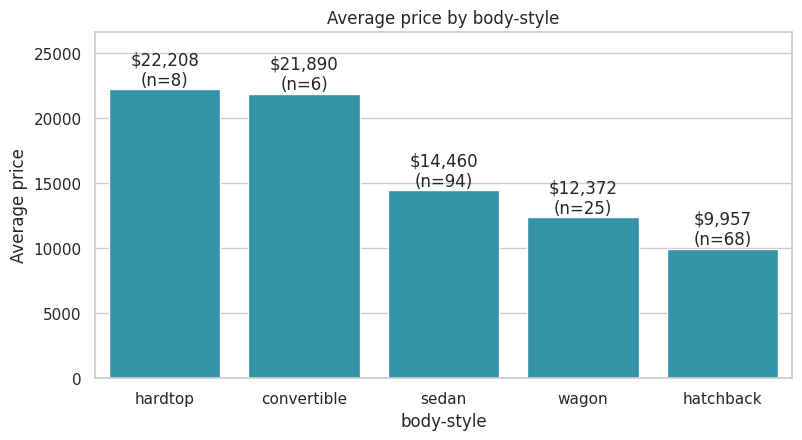

In [58]:
bs = (df.groupby("body-style")["price"]
        .agg(["count", "mean", "median", "min", "max"])
        .round(0).sort_values("mean", ascending=False))
print(bs)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=bs.index, y=bs["mean"], ax=ax, color="#219ebc")
for i, (m, n) in enumerate(zip(bs["mean"], bs["count"])):
    ax.text(i, m + 300, f"${m:,.0f}\n(n={n})", ha="center")
ax.set_ylabel("Average price"); ax.set_title("Average price by body-style")
ax.set_ylim(0, bs["mean"].max() * 1.2)
plt.show()

**Explanation.**

**Hardtops ($22,208) and convertibles ($21,890) have the highest average prices**, while **hatchbacks** are the cheapest ($9,957). Sedans ($14,460) and wagons ($12,372) are in between. Hardtops and convertibles are low-volume, premium body styles (only 8 and 6 cars here), so their averages come from few cars.

## 3.3 Average price by drive-wheels and body-style together

Average price:
body-style    convertible  hardtop  hatchback    sedan    wagon
drive-wheels                                                   
4wd                   NaN      NaN     7603.0  12647.0   9096.0
fwd               11595.0   8249.0     8396.0   9812.0   9997.0
rwd               23950.0  24203.0    14338.0  21712.0  16994.0

Number of cars:
body-style    convertible  hardtop  hatchback  sedan  wagon
drive-wheels                                               
4wd                   NaN      NaN        1.0    3.0    4.0
fwd                   1.0      1.0       49.0   55.0   12.0
rwd                   5.0      7.0       18.0   36.0    9.0


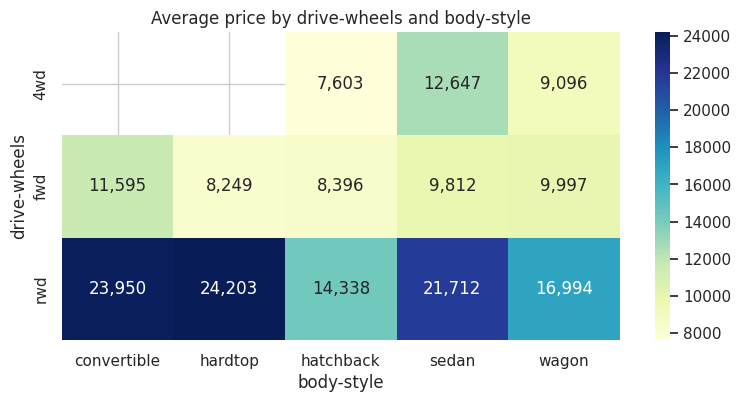

In [59]:
pivot = df.pivot_table(values="price", index="drive-wheels", columns="body-style", aggfunc="mean").round(0)
counts = df.pivot_table(values="price", index="drive-wheels", columns="body-style", aggfunc="count")
print("Average price:"); print(pivot); print("\nNumber of cars:"); print(counts)

plt.figure(figsize=(9, 4))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="YlGnBu")
plt.title("Average price by drive-wheels and body-style"); plt.show()

**Explanation.** The heatmap shows that **drive-wheels matters within every body style**: rear-wheel drive is the most expensive row in every column.

**Explanation**

**Rear-wheel** drive cars are the most expensive on average about $19,758, roughly twice the price of front-wheel drive cars, which are the cheapest (about $9,245).

4-wheel drive cars average about $10,241, but there are only 8 of them, so that figure is less reliable.

Rear-wheel drive is typical of sports and luxury cars, which explains the premium.

## 3.4 Average price by make (additional grouping)
Brand also looks like an important grouping, so I include it.

               count     mean
make                         
chevrolet          3   6007.0
dodge              9   7875.0
plymouth           7   7963.0
honda             13   8185.0
subaru            12   8541.0
isuzu              2   8916.0
mitsubishi        13   9240.0
renault            2   9595.0
toyota            32   9886.0
volkswagen        12  10078.0
nissan            18  10416.0
mazda             17  10653.0
saab               6  15223.0
peugot            11  15489.0
alfa-romero        3  15498.0
mercury            1  16503.0
audi               6  17859.0
volvo             11  18063.0
bmw                8  26119.0
porsche            4  31400.0
mercedes-benz      8  33647.0
jaguar             3  34600.0


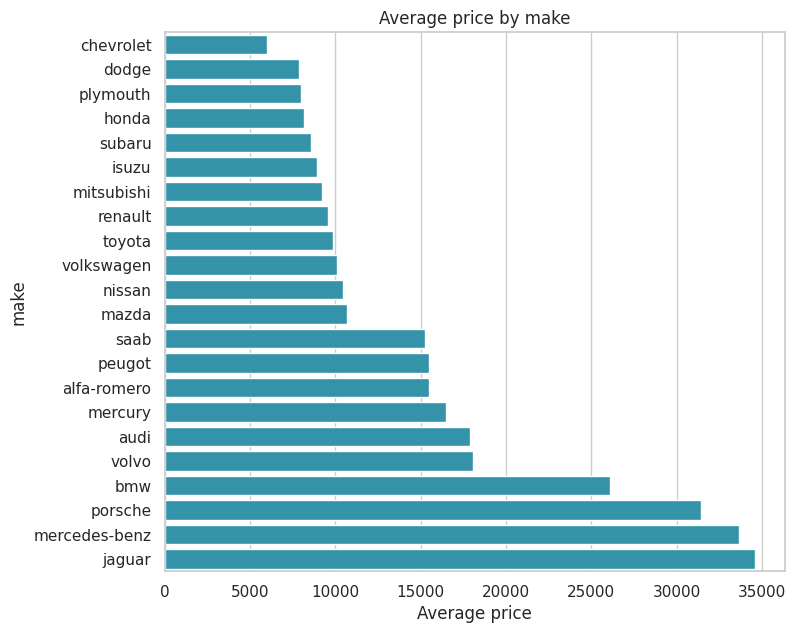

In [67]:
mk = (df.groupby("make")["price"].agg(["count", "mean"]).round(0).sort_values("mean"))
print(mk)

plt.figure(figsize=(8, 7))
sns.barplot(x=mk["mean"], y=mk.index, color="#219ebc")
plt.xlabel("Average price"); plt.title("Average price by make"); plt.show()

**Explanation.**

**Brand** creates the biggest price gap of all the groupings:

Jaguar 34,600 and Mercedes-Benz 33,647 are the most expensive, while Chevrolet $6,007 is the cheapest , followed by Dodge 7,875. The gap between the top and bottom brand is more than five-fold, so make is a strong candidate driver of price.

## 3.5 Answer to Question 3
- **Highest-priced groups:** rear-wheel drive (drive type); hardtop and convertible (body style); rear-wheel drive hardtop/convertible (combination); Jaguar and Mercedes-Benz (make).
- **Lowest-priced groups:** front-wheel drive (drive type, among groups with enough cars); hatchback (body style); Chevrolet (make).

---
# Question 4: Effect of the independent attributes on price

## 4(a) Continuous variables vs price


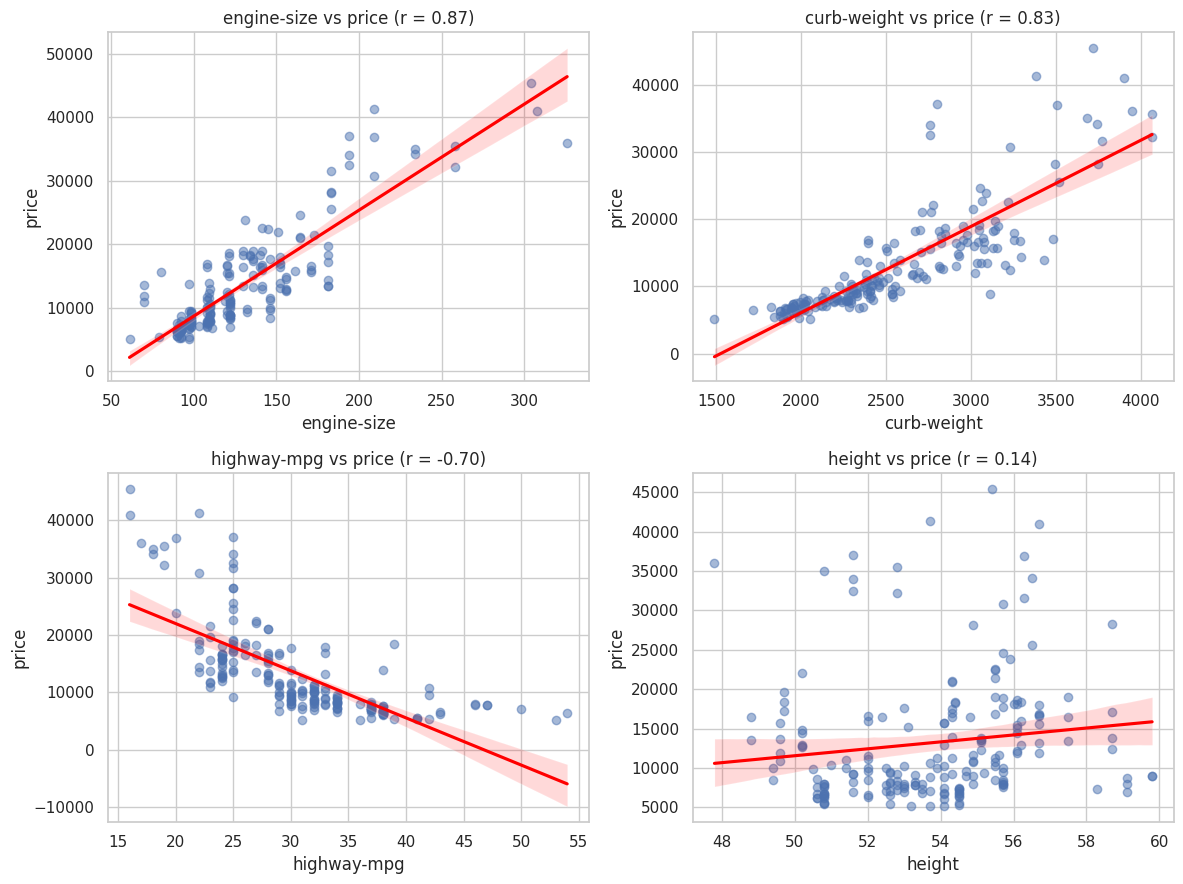

In [61]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.ravel(), ["engine-size", "curb-weight", "highway-mpg", "height"]):
    sns.regplot(x=col, y="price", data=df, ax=ax,
                scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
    r = df[col].corr(df["price"])
    ax.set_title(f"{col} vs price (r = {r:.2f})")
plt.tight_layout()
plt.show()

**Explanation.**
- **Engine size and curb weight (top row, left and right):** the dots rise from bottom-left to top-right and r is high. Bigger engines and heavier cars cost more.
- **Highway mpg (bottom left):** the line slopes downwards. Cars that use less fuel per distance (higher mpg) are cheaper, because small economy cars are cheap.
- **Height (bottom right):** the dots are scattered with no clear direction and r is close to 0, so height has almost no effect on price.

Now the same check for all the continuous variables, in one table and one chart.

         variable  pearson_r  spearman_rho      p_value  significant (p<0.05)
      engine-size      0.872         0.828 9.265492e-64                  True
      curb-weight      0.834         0.914 2.189577e-53                  True
       horsepower      0.810         0.849 6.369057e-48                  True
     city-L/100km      0.790         0.831 3.903106e-44                  True
            width      0.751         0.812 9.200336e-38                  True
      highway-mpg     -0.705        -0.827 1.749547e-31                  True
           length      0.691         0.810 8.016477e-30                  True
         city-mpg     -0.687        -0.831 2.321132e-29                  True
       wheel-base      0.585         0.682 8.076488e-20                  True
             bore      0.543         0.646 8.049189e-17                  True
           height      0.135         0.264 5.514627e-02                 False
normalized-losses      0.134         0.202 5.789749e-02         

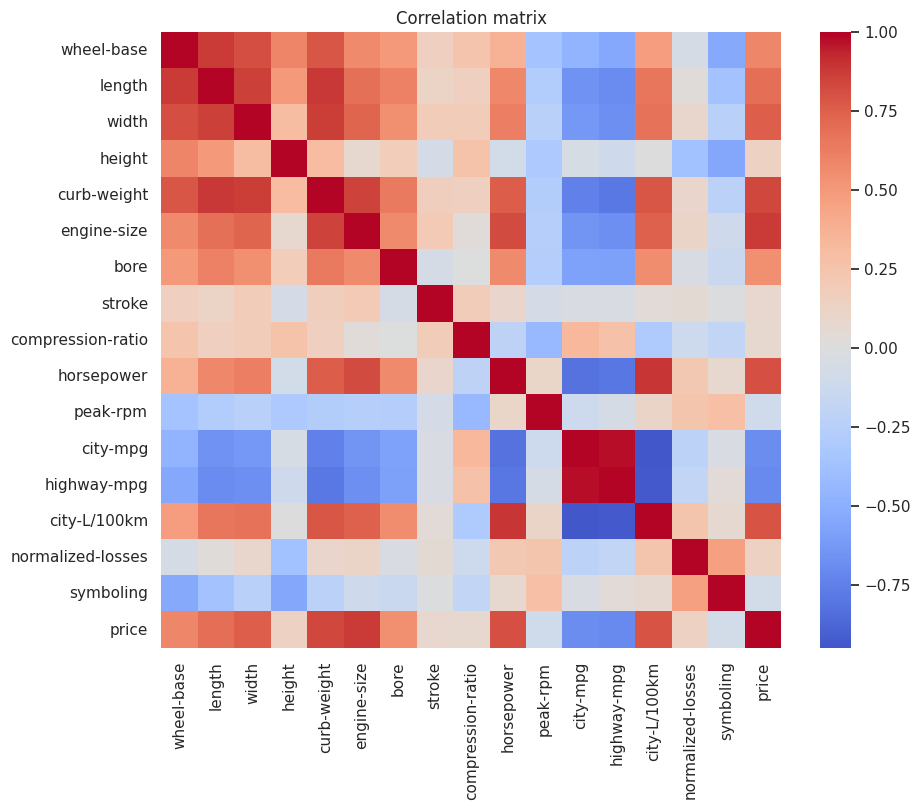

In [62]:
cont_for_corr = ["wheel-base", "length", "width", "height", "curb-weight", "engine-size",
                 "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm",
                 "city-mpg", "highway-mpg", "city-L/100km", "normalized-losses", "symboling"]

res = []
for c in cont_for_corr:
    r, p = stats.pearsonr(df[c], df["price"])
    rho, _ = stats.spearmanr(df[c], df["price"])
    res.append([c, round(r, 3), round(rho, 3), p])
corr_tbl = (pd.DataFrame(res, columns=["variable", "pearson_r", "spearman_rho", "p_value"])
              .sort_values("pearson_r", key=abs, ascending=False))
corr_tbl["significant (p<0.05)"] = corr_tbl["p_value"] < 0.05
print(corr_tbl.to_string(index=False))

plt.figure(figsize=(10, 8))
sns.heatmap(df[cont_for_corr + ["price"]].corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation matrix"); plt.show()

**Explanation.** The table ranks the continuous variables by the strength of their linear relationship with price (Pearson r), and Spearman's rho confirms the ranking without assuming a straight-line relationship.
- **Strongest:** `engine-size` (r about 0.87), `curb-weight` (0.83), `horsepower` (0.81), `city-L/100km` (0.79) and `width` (0.75). All are statistically significant (p < 0.05).
- **Moderate:** `length` (0.69), `wheel-base` (0.58), `bore` (0.54), and the negative `highway-mpg` (-0.70) and `city-mpg` (-0.69).
- **Weak and not significant (p > 0.05):** `height`, `normalized-losses`, `peak-rpm`, `stroke`, `symboling` and `compression-ratio` (all under 0.15 in absolute value).

The heatmap also shows that the strong predictors are **highly correlated with each other** (for example engine size, weight and horsepower), so they overlap in the information they carry. This matters for feature selection in Question 5.

## 4(b) Categorical variables vs price

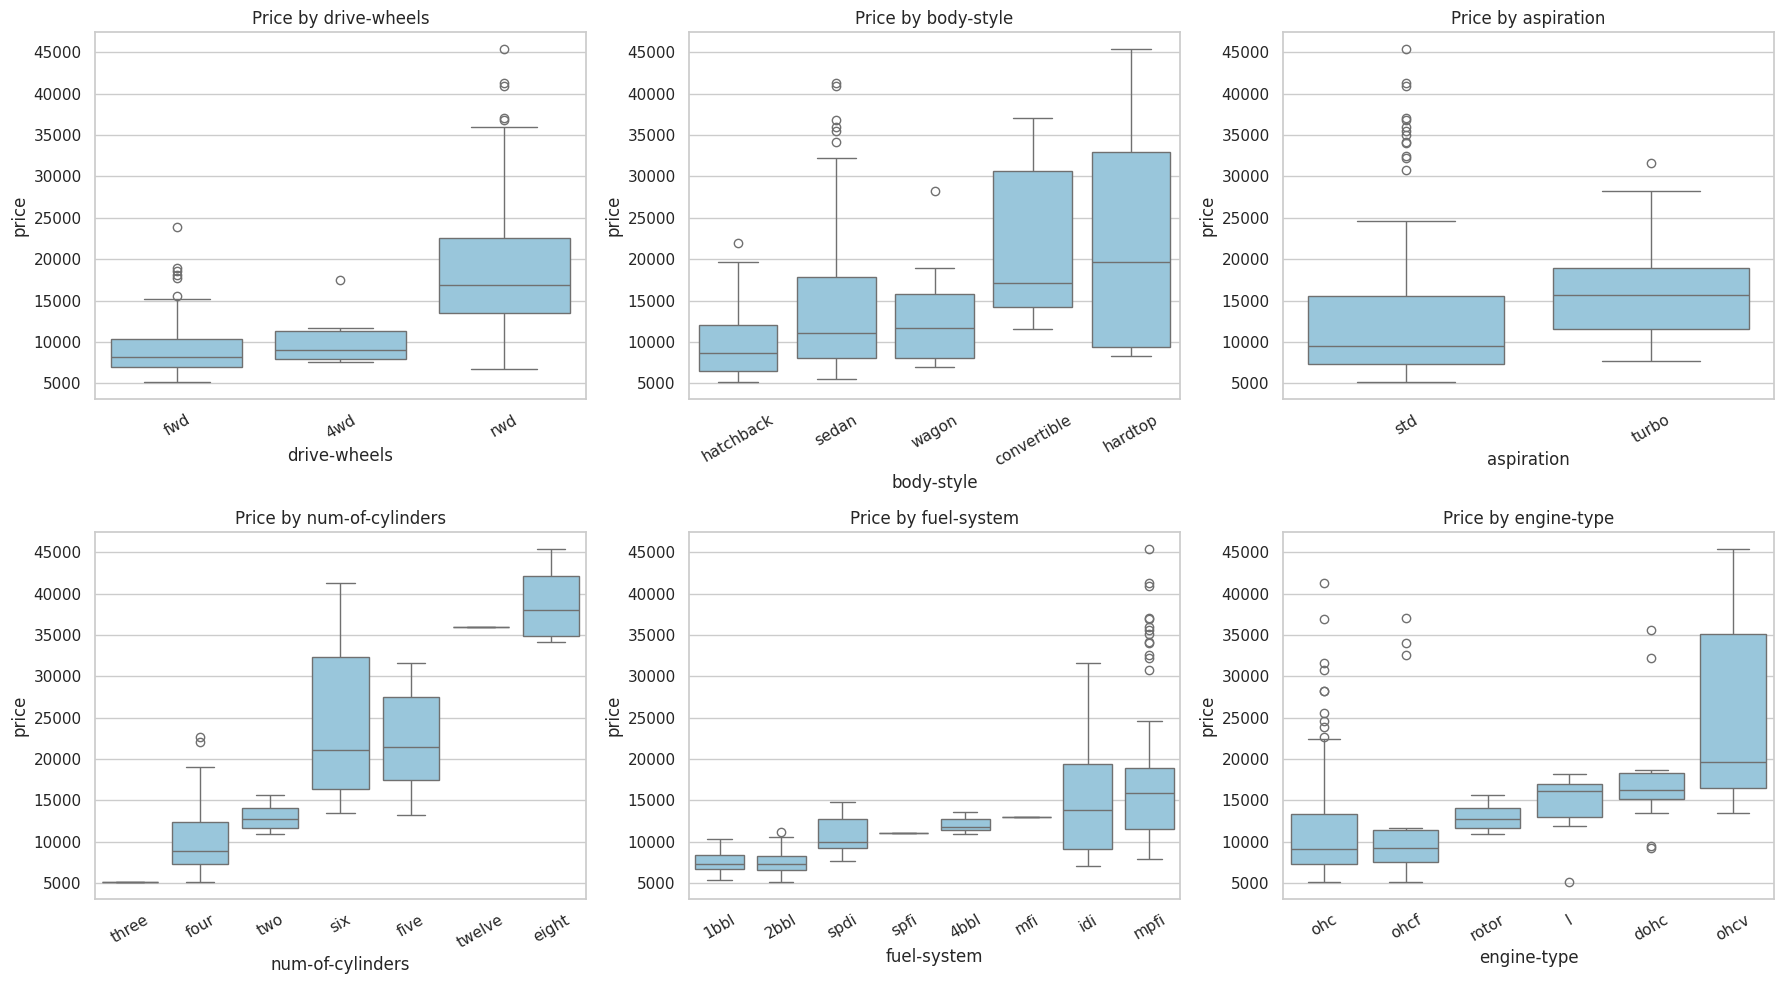

In [63]:
cat_vs_price = ["drive-wheels", "body-style", "aspiration", "num-of-cylinders",
                "fuel-system", "engine-type"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, c in zip(axes.ravel(), cat_vs_price):
    order = df.groupby(c)["price"].median().sort_values().index
    sns.boxplot(x=c, y="price", data=df, order=order, ax=ax, color="#8ecae6")
    ax.set_title(f"Price by {c}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**Explanation.** The boxplots show how price changes across categories, ordered by median price.
- **Drive-wheels:** rear-wheel drive has a much higher price range than front-wheel drive.
- **Body-style:** convertibles and hardtops are clearly higher; hatchbacks are lowest.
- **Aspiration:** turbo cars are generally more expensive than standard cars, though the ranges overlap.
- **Cylinders:** price rises with the number of cylinders (eight and twelve-cylinder cars are the most expensive, although there are only a handful of them).

In [64]:
results = []
for col in ["make", "num-of-cylinders", "drive-wheels", "body-style", "aspiration", "num-of-doors"]:
    groups = [g["price"] for _, g in df.groupby(col)]
    f_stat, p_value = stats.f_oneway(*groups)
    results.append([col, p_value])

anova = pd.DataFrame(results, columns=["variable", "p_value"])
anova["real difference in price?"] = np.where(anova["p_value"] < 0.05, "Yes", "No")
anova["p_value"] = anova["p_value"].apply(lambda p: f"{p:.4f}" if p >= 0.0001 else "< 0.0001")
anova

,variable,p_value,real difference in price?
0,make,< 0.0001,Yes
1,num-of-cylinders,< 0.0001,Yes
2,drive-wheels,< 0.0001,Yes
3,body-style,< 0.0001,Yes
4,aspiration,0.0107,Yes
5,num-of-doors,0.5497,No


**Explanation.**
- **`make`, `num-of-cylinders`, `drive-wheels` and `body-style`** all have p-values far below 0.05, so average price really does differ between their categories.
- **`aspiration`** is also below 0.05 (about 0.01), so turbo cars really are more expensive, though the effect is smaller.
- **`num-of-doors`** has a p-value well above 0.05 (about 0.55). So the number of doors does **not** change the average price.

**Takeaway:** brand (make), number of cylinders and drive type have the strongest effect on price among the categorical variables.

drive-wheels  4wd  fwd  rwd
body-style                 
convertible     0    1    5
hardtop         0    1    7
hatchback       1   49   18
sedan           3   55   36
wagon           4   12    9


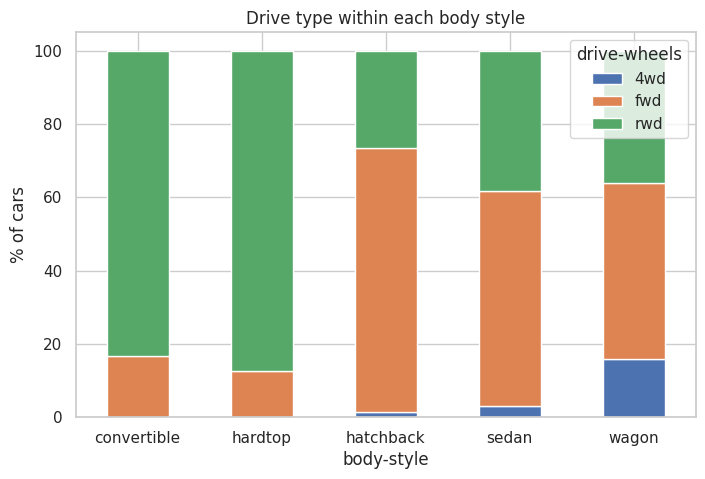

Chi-square p-value = 0.0003


In [65]:
table = pd.crosstab(df["body-style"], df["drive-wheels"])
print(table)

# Percentages within each body style, for the chart
percent = pd.crosstab(df["body-style"], df["drive-wheels"], normalize="index") * 100
percent.plot(kind="bar", stacked=True, figsize=(8, 5))
plt.ylabel("% of cars")
plt.title("Drive type within each body style")
plt.xticks(rotation=0)
plt.show()

chi2, p_value, dof, expected = stats.chi2_contingency(table)
print(f"Chi-square p-value = {p_value:.4f}")

**Explanation.**
- Most **hatchbacks are front-wheel drive** (49 of 68).
- Most **convertibles (5 of 6) and hardtops (7 of 8) are rear-wheel drive**.
- **Sedans** are a mix, but lean towards front-wheel drive.

The p-value is about 0.0003, far below 0.05, so **body style and drive type are linked**. (A small warning: some groups have very few cars, so treat the result as a good guide, not an exact measurement.)

**Why this matters for price:** convertibles and hardtops are expensive partly because they are almost always rear-wheel drive. The two effects overlap, so we should not add them up as if they were completely separate.

---
# Question 5: Main variables that affect price, and a recommendation [5 marks]

## Feature selection
**What is feature selection?** Choosing the few variables that matter most for predicting the target (here, price) and ignoring the rest.

**Method used: `SelectKBest` with the F-test.** It gives every numeric variable a score: the **higher the score, the stronger the link with price**. Then it keeps the top 5. (Categorical variables were already tested with ANOVA in Question 4b.)

Score of each variable (higher = stronger link with price):
engine-size          634.0
curb-weight          456.0
horsepower           378.0
city-L/100km         330.0
width                258.0
highway-mpg          196.0
length               181.0
city-mpg             177.0
wheel-base           103.0
bore                  83.0
height                 4.0
normalized-losses      4.0
peak-rpm               2.0
symboling              1.0
stroke                 1.0
compression-ratio      1.0
dtype: float64

Top 5 variables selected: ['width', 'curb-weight', 'engine-size', 'horsepower', 'city-L/100km']


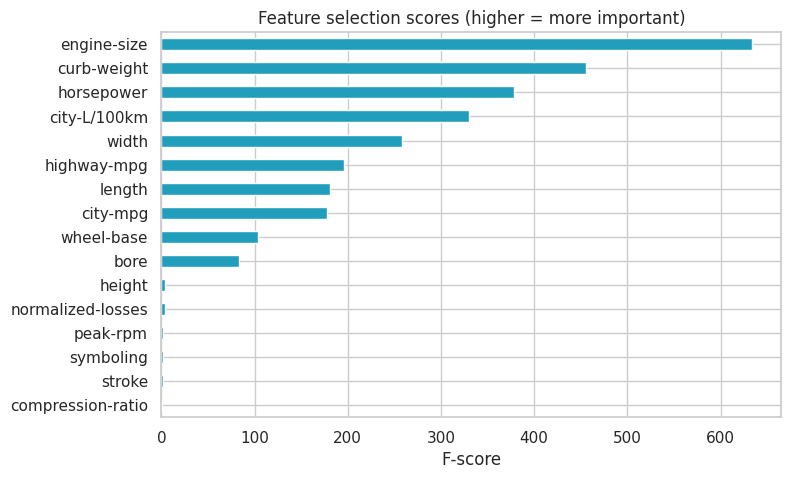

In [66]:
from sklearn.feature_selection import SelectKBest, f_regression

X = df[cont_for_corr]          # the 13 numeric variables from Question 4(a)
y = df["price"]

selector = SelectKBest(score_func=f_regression, k=5).fit(X, y)

scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
print("Score of each variable (higher = stronger link with price):")
print(scores.round(0))

print("\nTop 5 variables selected:", list(X.columns[selector.get_support()]))

scores.sort_values().plot(kind="barh", figsize=(8, 5), color="#219ebc")
plt.title("Feature selection scores (higher = more important)")
plt.xlabel("F-score")
plt.show()

**Explanation.** The method selected these **top 5 numeric variables: `engine-size`, `curb-weight`, `horsepower`, `width` and `highway-mpg`**. They have by far the highest scores in the chart, while variables such as `peak-rpm`, `stroke` and `compression-ratio` score close to zero and can be ignored. This agrees with the correlations in Question 4(a).

## Main variables that have the most impact on price

| Variable | Why it matters |
|---|---|
| **Engine size** | Highest score and correlation (0.87): bigger engine, higher price |
| **Curb weight** | Second highest (0.83): heavier cars cost more |
| **Horsepower** | Third (0.81): more powerful cars cost more |
| **Width and highway mpg** | Also selected: wider cars cost more, and cars with better fuel economy cost less |
| **Make (brand)** | Prices differ strongly between brands (Question 3 and 4b) |
| **Drive-wheels** | Rear-wheel drive costs about twice as much as front-wheel drive |
| **Number of cylinders** | More cylinders, higher price (Question 4b) |

**Important note:** engine size, curb weight, horsepower and width all describe the same thing: *how big and powerful the car is*. So they are really one main driver, not four separate ones. Also, this analysis shows that these variables are **linked** to price; it does not prove that they **cause** it.

## Recommendation for a car dealer
1. **Start with the size and power of the car.** Engine size, weight and horsepower are the best guide to price. Use them to set a starting price.
2. **Then adjust for the brand.** Luxury makes (Jaguar, Mercedes-Benz, BMW, Porsche) sell for much more than economy makes (Chevrolet, Dodge), so do not price a luxury car using economy-car prices.
3. **Add a premium for rear-wheel drive, convertibles and hardtops.** These have the highest average prices. Hatchbacks and front-wheel drive cars sell for the least.
4. **Ignore weak factors.** Height, peak RPM, compression ratio, stroke and number of doors have no real effect on price, so they should not change the price.
5. **Use these as a guide, not a fixed rule.** The data has only 201 cars, and some groups (convertibles, hardtops, 4-wheel drive) are very small, so check against current market prices.

---
## Conclusion
After cleaning (4 missing `stroke` values and 1 missing `horsepower-binned` value filled, no duplicates found, luxury-car outliers kept as genuine), the analysis shows that car price is mostly determined by **how large and powerful the car is (engine size, curb weight, horsepower)** and by **brand**, with **drive type** (rear-wheel drive costs more), **body style** and **number of cylinders** adding further effects. Dealers should set prices starting from engine size and power, then adjust for make, drive type and body style.